In [48]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_dataset import laod_dataframes



import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.sparse import csr_matrix
from sklearn import config_context
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from surprise import SVD, Dataset, Reader, accuracy
from wordcloud import WordCloud
import os
from pathlib import Path



RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

plt.style.use('dark_background')

### Построение прототипа книжного рекомендательного сервиса
## 1. Знакомство с данными и EDA (Exploratory Data Analysis)

In [49]:
dataset_dict = laod_dataframes()

df_books = dataset_dict["df_books"]
df_ratings = dataset_dict["df_ratings"]
df_book_tags = dataset_dict["df_book_tags"]
df_tags = dataset_dict["df_tags"]
df_to_read = dataset_dict["df_to_read"]

## 1.1. Проведем первичный EDA , убедимся в отсуствии пропусков или полных дублей.

In [50]:
for name,dataset in dataset_dict.items():
  display(Markdown(f"{name}: {len(dataset):,} строк, {dataset.shape[1]} столбцов."))
  display(dataset.head(3))
  display(Markdown(f"Пропущено значений: {dataset.isna().sum().sum()}."))
  display(Markdown(f"Полных дубликатов: {dataset.duplicated().sum()}."))

df_books: 10,000 строк, 23 столбцов.

,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...


Пропущено значений: 2975.

Полных дубликатов: 0.

df_ratings: 981,756 строк, 3 столбцов.

...

Полных дубликатов: 0.

df_to_read: 912,705 строк, 2 столбцов.

,user_id,book_id
0,1,112
1,1,235
2,1,533


Пропущено значений: 0.

Полных дубликатов: 0.

Проверим подробнее df_books и df_ratings.

In [51]:
df_books = dataset_dict["df_books"]
missing_columns = df_books.columns[df_books.isna().any()].tolist()
display(f"Столбцы с пропусками: {missing_columns}")

"Столбцы с пропусками: ['isbn', 'isbn13', 'original_publication_year', 'original_title', 'language_code']"

Заполним пропуски в original_title из title.

In [52]:
df_books['original_title'] = df_books['original_title'].fillna(df_books['title'])
display(df_books.head(3))
print(f'Проверка')
display(Markdown(f"Пропущено значений df_books['original_title']: {df_books['original_title'].isna().sum()}"))

,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...


Проверка


Пропущено значений df_books['original_title']: 0

Проверим что, у нас датафрейме df_ratings нет ли пользователей, которые голосовали дважды.

In [53]:
df_ratings[df_ratings.duplicated(subset=["user_id", "book_id"],keep=False)].head(10)

,book_id,user_id,rating
1170,12,40251,4
1171,12,40251,4
2473,25,32635,5
2474,25,32635,5
2717,28,9011,2
2718,28,9011,1
2946,30,24582,4
2947,30,24582,3
2958,30,31760,4
2959,30,31760,4


Так как пользователи которые ставили оценку несколько раз но по разному, возьмем среднее и при обучении будем работать с ним.

In [54]:
ratings = df_ratings.groupby(["user_id", "book_id"], as_index=False)["rating"].mean()
book_columns = ["original_title", "authors", "average_rating", "ratings_count"]
print(f"После объединения: {len(ratings):,} оценок, "
      f"{ratings.user_id.nunique():,} пользователей, {ratings.book_id.nunique():,} книг")

После объединения: 979,478 оценок, 53,424 пользователей, 10,000 книг


## 1.2 Распределение оценок
Показываем исходные  оценки до усреднения повторных пар.

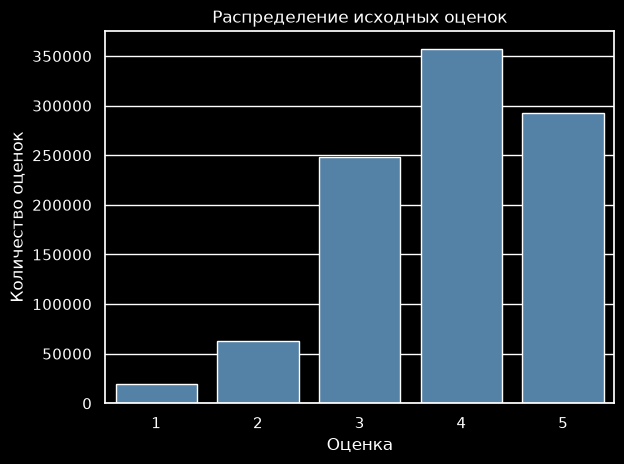

Доля оценок 4 и 5: 66.2%


In [55]:
ratings_count = df_ratings['rating'].value_counts().sort_index()
sns.barplot(x=ratings_count.index, y=ratings_count.values, color="steelblue")
plt.xlabel("Оценка")
plt.ylabel("Количество оценок")
plt.title("Распределение исходных оценок")
plt.tight_layout()
plt.show()
part_45=len(df_ratings.loc[df_ratings['rating']>=4, 'rating'])/len(df_ratings)
print(f"Доля оценок 4 и 5: {part_45:.1%}")

Оценки смещены в сторону высоких оценок, 4 и 5.

## 1.3 Активность пользователей и популярность книг

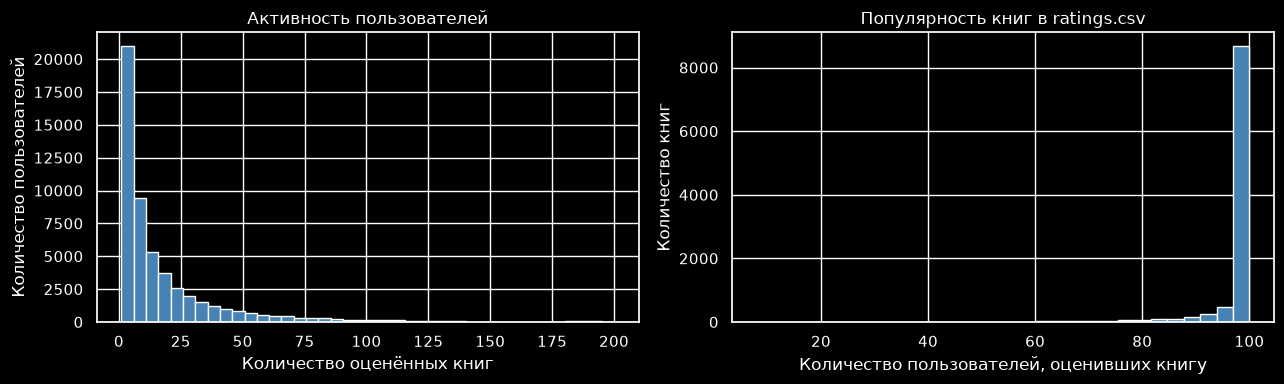

Пользователи с 1–5 книгами: 20,985 (39.3%)
90-й процентиль активности: 47 оценок
Книги с не более чем 40 оценками: 5
90-й процентиль популярности: 100 оценок
Заполненность матрицы оценок: 0.183%


In [56]:
user_activity = ratings.groupby("user_id")['rating'].agg('count')
book_activity = ratings.groupby("book_id")['rating'].agg('count')

#определим пороговые значения, число людей с 1-5 книгами и количество высокооценненых книг
active_threshold = user_activity.quantile(0.9)
popular_threshold = book_activity.quantile(0.9)
user_1_5 = user_activity[user_activity<=5].count()
user_total = user_activity.count()
books_40 = book_activity[book_activity<=40].count()
books_total = book_activity.count()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(user_activity, bins=40, color="steelblue")
axes[0].set(xlabel="Количество оценённых книг", ylabel="Количество пользователей",
            title="Активность пользователей")
axes[1].hist(book_activity, bins=30, color="steelblue")
axes[1].set(xlabel="Количество пользователей, оценивших книгу", ylabel="Количество книг",
            title="Популярность книг в ratings.csv")
plt.tight_layout()
plt.show()


print(f"Пользователи с 1–5 книгами: {user_1_5:,} ({user_1_5/user_total:.1%})")
print(f"90-й процентиль активности: {active_threshold:g} оценок")
print(f"Книги с не более чем 40 оценками: {books_40:,}")
print(f"90-й процентиль популярности: {popular_threshold:g} оценок")
print(f"Заполненность матрицы оценок: {len(ratings) / (len(user_activity) * len(book_activity)):.3%}")


## 1.5. Частые теги



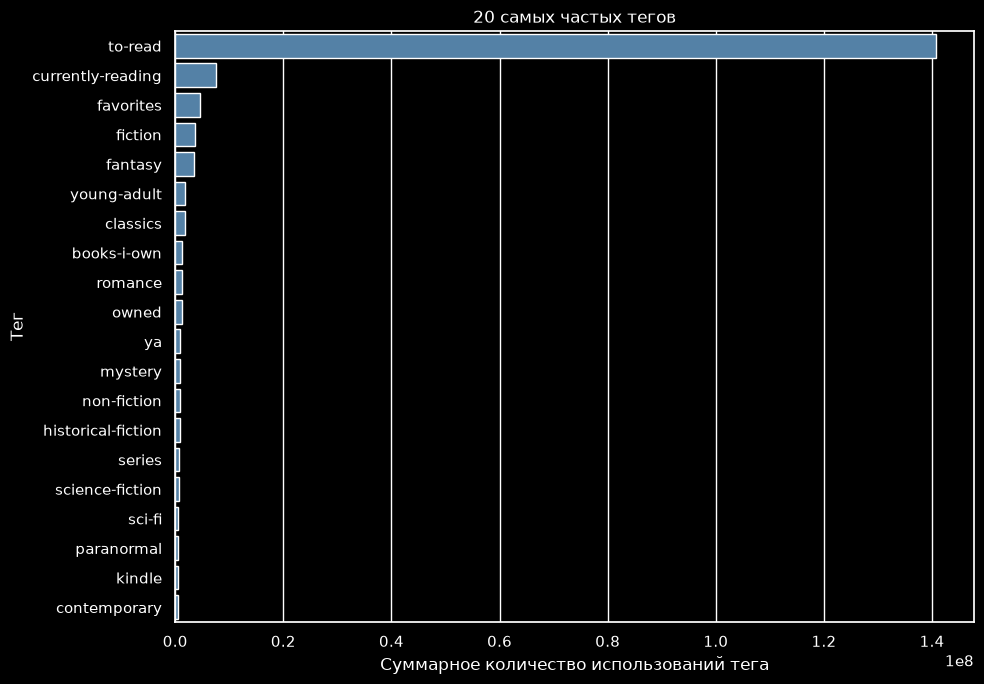

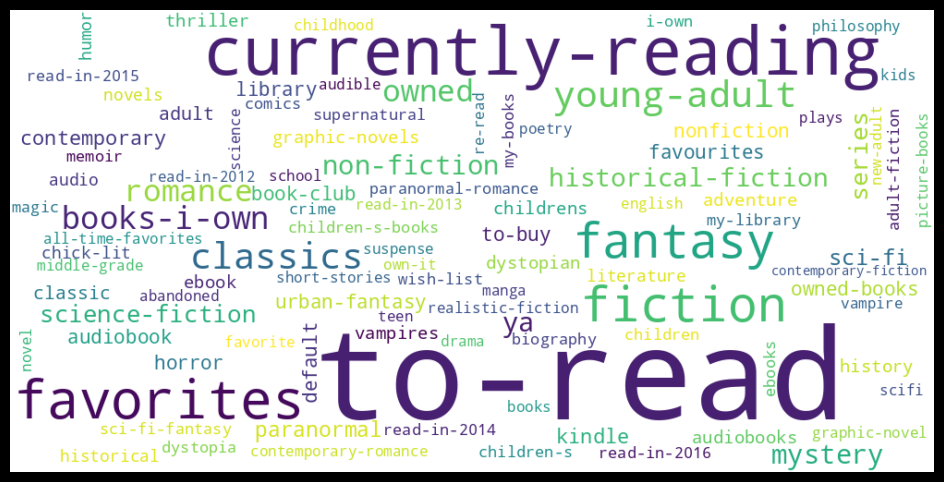

In [57]:
named_tags = df_book_tags.merge(df_tags, on="tag_id", how="left")
top_tags = named_tags.groupby("tag_name")["count"].sum().nlargest(100)

plt.figure(figsize=(10, 7))
sns.barplot(x=top_tags.head(20).values, y=top_tags.head(20).index, color="steelblue")
plt.xlabel("Суммарное количество использований тега")
plt.ylabel("Тег")
plt.title("20 самых частых тегов")
plt.tight_layout()
plt.show()

#нарисуем красивую визуализацию
wordcloud = WordCloud(width=1000, height=500, background_color="white",
                      random_state=RANDOM_STATE).generate_from_frequencies(top_tags.to_dict())
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

# 1.6 Выводы
Оценки смещены в сторону высоких. У 39.3% пользователей не более 5 оценённых книг, у остальных 60.7% — больше 5. Матрица оценок очень разреженная.
Пользователи с 1–5 книгами: 20,985 (39.3%)
90-й процентиль активности: 47 оценок
Книги с не более чем 40 оценками: 5
90-й процентиль популярности: 100 оценок
Заполненность матрицы оценок: 0.183%

# 2. Базовая и контентная модели
## 2.1. Рекомендации по среднему рейтингу

In [58]:
def recommend_popular(books:pd.DataFrame, min_ratings:int=1000, n:int=10)-> list[int]:
  candidates = books.loc[books['ratings_count']>=min_ratings]
  return candidates.sort_values(["average_rating", "ratings_count"], ascending=False).head(n).index.tolist()


# отсортируем книги по id
catalog = df_books.set_index("id").sort_index()
recommended_ids = recommend_popular(catalog)
display(catalog.loc[recommended_ids, book_columns])

,original_title,authors,average_rating,ratings_count
id,,,,
3628,The Complete Calvin and Hobbes,Bill Watterson,4.82,28900
862,Words of Radiance,Brandon Sanderson,4.77,73572
3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",4.77,33220
8854,Mark of the Lion Trilogy,Francine Rivers,4.76,9081
7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",4.76,8953
4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,4.75,22351
422,Complete Harry Potter Boxed Set,J.K. Rowling,4.74,190050
6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,4.74,16766
3753,"Harry Potter Collection (Harry Potter, #1-6)",J.K. Rowling,4.73,24618


## 2.2. Похожие книги по TF-IDF

In [59]:
# объединяем теги по книгам в одну строку, чтобы использовать их в качестве признаков
tags_by_book = named_tags.groupby("goodreads_book_id")["tag_name"].agg(" ".join)
profiles = df_books[["id", "book_id", "original_title"]].copy()
#объединяем теги с профилями книг
profiles = pd.merge(profiles, tags_by_book.rename("tags"), how="left", left_on="book_id", right_index=True)
profiles["text"] = (profiles["original_title"] + " " + profiles["tags"].fillna(""))

#создаём Series для быстрого поиска позиции книги по её id
profile_positions = pd.Series(np.arange(len(profiles)), index=profiles["id"])

#создаём TF-IDF матрицу для текстов профилей книг
tfidf = TfidfVectorizer(stop_words="english", max_features=20_000)
tfidf_matrix = tfidf.fit_transform(profiles["text"])
print("Размерность TF-IDF:", tfidf_matrix.shape)


def get_similar_books(book_id:int, n:int=5):
    #ищем позицию книги в профилях по её id
    position = profile_positions.loc[book_id]
    #ищем косинусное сходство между профилем книги и всеми остальными профилями
    scores = cosine_similarity(tfidf_matrix[position], tfidf_matrix).ravel()
    #исключаем саму книгу из результатов поиска
    scores[position] = -np.inf
    #ищем индексы n наиболее похожих книг и возвращаем их id в порядке убывания сходства
    nearest = np.argsort(scores, kind="stable")[-n:]
    return profiles.iloc[nearest]["id"].tolist()[::-1]  

#тестируем функцию поиска похожих книг на примере книги с индексом 10
example_book = int(df_books.iloc[10]["id"])
print("Похожие на:", catalog.loc[example_book, "original_title"])
display(catalog.loc[get_similar_books(example_book, n=10), book_columns])

Размерность TF-IDF: (10000, 20000)
Похожие на: The Kite Runner 


,original_title,authors,average_rating,ratings_count
id,,,,
67,A Thousand Splendid Suns,Khaled Hosseini,4.34,818742
359,And The Mountains Echoed,Khaled Hosseini,4.03,199326
28,Lord of the Flies,William Golding,3.64,1605019
8,The Catcher in the Rye,J.D. Salinger,3.79,2044241
5,The Great Gatsby,F. Scott Fitzgerald,3.89,2683664
595,A Separate Peace,John Knowles,3.56,155901
4,To Kill a Mockingbird,Harper Lee,4.25,3198671
90,The Outsiders,S.E. Hinton,4.06,659248
417,The Thirteenth Tale,Diane Setterfield,3.95,213200


## 3. Коллаборативная фильтрация (Collaborative Filtering — CF)
### 3.1. Матрица взаимодействий «пользователь — книга»

Используем явные оценки из `ratings`, где повторы уже усреднены.
Строки — пользователи, столбцы — книги. Ноль означает отсутствие оценки.
Для примера построим плотную матрицу средствами pandas на первых 1000 оценках.
На всех данных она занимает около 4 ГиБ, поэтому ниже используем разреженную матрицу.

In [60]:
df_user_book = ratings.head(1000).pivot(index="user_id", columns="book_id", values="rating").fillna(0)
similarity_matrix = cosine_similarity(df_user_book.T)
np.fill_diagonal(similarity_matrix, 0)
item_similarity = pd.DataFrame(
    similarity_matrix,
    index=df_user_book.columns,
    columns=df_user_book.columns
)
del similarity_matrix
display(df_user_book.iloc[:5, :5])
display(item_similarity.iloc[:5, :5])

display(f'размер в мегабайтах item_similarity: {item_similarity.memory_usage(deep=True).sum() / 1024 ** 2:.2f} МБ')
display(f'размер в мегабайтах df_user_book: {df_user_book.memory_usage(deep=True).sum() / 1024 ** 2:.2f} МБ')

# Освобождаем матрицы демонстрационного примера.
del df_user_book, item_similarity


book_id,78,108,120,135,137
user_id,,,,,
1,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0


book_id,78,108,120,135,137
book_id,,,,,
78,0.0,1.0,1.0,1.0,1.0
108,1.0,0.0,1.0,1.0,1.0
120,1.0,1.0,0.0,1.0,1.0
135,1.0,1.0,1.0,0.0,1.0
137,1.0,1.0,1.0,1.0,0.0


'размер в мегабайтах item_similarity: 5.83 МБ'

'размер в мегабайтах df_user_book: 0.56 МБ'

Плотная матрица хранит и пропуски, поэтому занимает много памяти.
Далее строим разреженную матрицу на всех оценках.


### 3.1. Матрица взаимодействий «пользователь — книга»

Используем явные оценки из `ratings`, где повторы уже усреднены.
Строки — пользователи, столбцы — книги. Ноль означает отсутствие оценки.
Матрица разреженная: храним только оценки, чтобы экономить память.

In [61]:
#данные для построения разреженной матрицы оценок
data = ratings['rating'].to_numpy(dtype=np.float32)
# Строки и столбцы для разреженной матрицы
row_indices =pd.Categorical(ratings['user_id'])
col_indices = pd.Categorical(ratings['book_id'])

# создаём разреженную матрицу оценок пользователей
user_book_matrix = csr_matrix(
    (data, (row_indices.codes, col_indices.codes)),
    shape=(len(row_indices.categories), len(col_indices.categories))
)


### 3.2. Разреженный граф схожести книг

Храним не все пары книг, а до `ITEM_NEIGHBORS = 100` ближайших соседей каждой
книги с положительным косинусным сходством. Поиск точный, блочный:
`working_memory=64` ограничивает рабочую память расчёта расстояний, но не всю
память процесса. Полная плотная матрица 10 000 × 10 000 не сохраняется.
Граф CSR занимает O(число книг × число соседей); он направленный, поскольку
списки ближайших соседей могут различаться. Нулевая диагональ исключает саму книгу.
Число соседей фиксируем до оценки, а не подбираем на test.

Раздел 3 иллюстрирует алгоритм на всех данных. Для итоговых метрик в разделе 5
граф будет заново построен исключительно по train.


In [62]:
ITEM_NEIGHBORS = 100


def build_item_neighbors(interactions, n_neighbors=ITEM_NEIGHBORS):
    if not isinstance(n_neighbors, (int, np.integer)) or n_neighbors < 1:
        raise ValueError("n_neighbors должно быть положительным целым числом")
    item_vectors = interactions.T.tocsr().astype(np.float32)
    n_items = item_vectors.shape[0]
    if n_items < 2:
        return csr_matrix((n_items, n_items), dtype=np.float32)
    neighbors = NearestNeighbors(
        n_neighbors=min(n_neighbors, n_items - 1), metric="cosine", algorithm="brute"
    ).fit(item_vectors)
    with config_context(working_memory=64):
        graph = csr_matrix(neighbors.kneighbors_graph(mode="distance"))
    graph.data = np.maximum(1.0 - graph.data, 0.0).astype(np.float32)
    graph.setdiag(0)
    graph.eliminate_zeros()
    graph.sort_indices()
    return graph


def rank_unseen(scores, item_ids, seen, n):
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n должно быть положительным целым числом")
    available = ~np.isin(item_ids, list(seen))
    positions = np.flatnonzero(available)
    # При равенстве оценок выбираем меньший ID: общий порядок для всех моделей.
    order = np.lexsort((item_ids[positions], -np.asarray(scores)[positions]))
    return item_ids[positions[order[:n]]].tolist()


def cf_scores_from_history(history, graph, fallback):
    scores = np.full(graph.shape[0], fallback, dtype=float)
    if history.nnz == 0:
        return scores
    weighted_sum = (graph @ history.T).toarray().ravel()
    observed = history.copy()
    observed.data = np.ones_like(observed.data)
    weights = (graph @ observed.T).toarray().ravel()
    np.divide(weighted_sum, weights, out=scores, where=weights > 0)
    return scores


item_similarity = build_item_neighbors(user_book_matrix)
display(pd.DataFrame(
    item_similarity[:5, :5].toarray(),
    index=col_indices.categories[:5], columns=col_indices.categories[:5]
))
graph_bytes = sum(a.nbytes for a in (
    item_similarity.data, item_similarity.indices, item_similarity.indptr
))
print(f"CSR-граф: {item_similarity.shape}, связей: {item_similarity.nnz:,}, "
      f"память: {graph_bytes / 1024**2:.2f} МиБ")


,1,2,3,4,5
1,0.000000,0.555526,0.509152,0.464656,0.480233
2,0.555526,0.000000,0.520216,0.610741,0.587944
3,0.509152,0.520216,0.000000,0.359108,0.344423
4,0.464656,0.610741,0.359108,0.000000,0.703334
5,0.480233,0.587944,0.344423,0.703334,0.000000


CSR-граф: (10000, 10000), связей: 999,208, память: 7.66 МиБ


### 3.3. Предсказание оценки

Для целевой книги используем её сохранённых ближайших соседей, которые есть
в истории пользователя. Прогноз — среднее оценок, взвешенное по косинусному
сходству. Если пересечений нет, возвращаем среднюю оценку пользователя;
для нового пользователя — среднюю оценку обучающих данных.
Это усечённый Item-kNN: он экономит память, но может отбросить полезного
соседа за пределами первых 100. Изменение относительно прежнего среднего
по пяти книгам из истории явно учитываем при интерпретации результатов.


In [63]:
global_mean = float(ratings["rating"].mean())


def predict_rating(user_id, book_id):
    if user_id not in row_indices.categories:
        return global_mean
    history = user_book_matrix.getrow(row_indices.categories.get_loc(user_id)).copy()
    # При прогнозе уже оценённой книги её собственная оценка не используется.
    if book_id in col_indices.categories:
        position = col_indices.categories.get_loc(book_id)
        history.data[history.indices == position] = 0
        history.eliminate_zeros()
    fallback = float(history.data.mean()) if history.nnz else global_mean
    if book_id not in col_indices.categories:
        return fallback
    scores = cf_scores_from_history(history, item_similarity, fallback)
    return float(scores[col_indices.categories.get_loc(book_id)])


In [64]:
example_user = row_indices.categories[0]
history = user_book_matrix.getrow(row_indices.categories.get_loc(example_user))
unread_positions = np.setdiff1d(np.arange(user_book_matrix.shape[1]), history.indices)
example_book_cf = col_indices.categories[unread_positions[0]]
print("Пользователь:", example_user)
print("Книга:", catalog.loc[example_book_cf, "original_title"])
print(f"Прогноз оценки: {predict_rating(example_user, example_book_cf):.2f}")


Пользователь: 1
Книга: The Hunger Games
Прогноз оценки: 3.67


### 3.4. Ограничения Item-Based CF

Новые пользователи не имеют истории, а у редких книг мало общих читателей.
Граф хранит только ближайших соседей, поэтому занимает меньше памяти, но
не учитывает все возможные совпадения. При отсутствии соседей прогноз
сводится к среднему пользователя: равные оценки упорядочиваются по ID,
что не является содержательной персонализацией. Нужен отдельный fallback,
например популярность или контентная модель; здесь ограничение оставлено
видимым, чтобы оценивать именно Item-Based CF.


## 4. Матричная факторизация и единое разделение данных

Временных меток нет, а порядок строк не подтверждён как хронологический.
Поэтому leave-last-out по этому порядку нельзя интерпретировать как прогноз
будущего. Используем воспроизводимый **per-user random holdout**: для каждого
пользователя с двумя и более книгами откладываем примерно 20% его оценок,
минимум одну, и сохраняем минимум одну в train. Единственная оценка
пользователя остаётся в train. Повторы пар уже объединены до разбиения.

Это оценка для пользователей с известной историей (warm-user), не для новых
пользователей. Случайное разбиение не моделирует временной дрейф. Все модели
раздела 5 используют эти же `train_df` и `test_df`; test не участвует в обучении,
построении пользовательских профилей и подборе параметров.


In [65]:
def per_user_split(frame, test_size=0.2, random_state=RANDOM_STATE):
    if not 0 < test_size < 1:
        raise ValueError("test_size должно находиться между 0 и 1")
    frame = frame.reset_index(drop=True)
    if frame.duplicated(["user_id", "book_id"]).any():
        raise ValueError("Сначала объедините повторные пары пользователь–книга")
    counts = frame.groupby("user_id")["book_id"].transform("size").to_numpy()
    n_test = np.where(
        counts >= 2,
        np.minimum(counts - 1, np.maximum(1, np.floor(counts * test_size).astype(int))),
        0,
    )
    random_keys = pd.Series(np.random.default_rng(random_state).random(len(frame)))
    within_user_rank = random_keys.groupby(frame["user_id"]).rank(method="first").to_numpy()
    is_test = within_user_rank <= n_test
    return frame.loc[~is_test].copy(), frame.loc[is_test].copy()


train_df, test_df = per_user_split(ratings)
assert len(train_df) + len(test_df) == len(ratings)
assert set(test_df["user_id"]) <= set(train_df["user_id"])
assert not pd.MultiIndex.from_frame(train_df[["user_id", "book_id"]]).isin(
    pd.MultiIndex.from_frame(test_df[["user_id", "book_id"]])
).any()

trainset = Dataset.load_from_df(
    train_df[["user_id", "book_id", "rating"]], Reader(rating_scale=(1, 5))
).build_full_trainset()
testset = list(test_df[["user_id", "book_id", "rating"]].itertuples(index=False, name=None))
book_ids = catalog.index.sort_values().to_numpy()
train_user_items = train_df.groupby("user_id")["book_id"].agg(set).to_dict()
print(f"Train: {len(train_df):,}, test: {len(test_df):,}")
print("Только в train (одна книга):", int((ratings.groupby("user_id").size() == 1).sum()))


Train: 788,503, test: 190,975
Только в train (одна книга): 42


### 4.1. Обучение SVD и оценка ошибки

Обучаем одну модель на общем train. RMSE и MAE рассчитываем по отложенным
оценкам. Эти метрики оценивают предсказание рейтинга, а не порядок top-N;
ранжирование отдельно проверяем в разделе 5. Параметры фиксируем заранее.


In [66]:
model = SVD(n_factors=50, n_epochs=20, lr_all=0.01, reg_all=0.02, random_state=RANDOM_STATE)
model.fit(trainset)
predictions = model.test(testset)
rmse = accuracy.rmse(predictions)
mae = accuracy.mae(predictions)

RMSE: 0.8465
MAE:  0.6558


In [67]:
def prepare_svd_catalog(fitted_model, item_ids):
    # Сопоставление raw ID и внутренних ID строится один раз после обучения.
    item_mapping = {fitted_model.trainset.to_raw_iid(i): i
                    for i in fitted_model.trainset.all_items()}
    biases = np.zeros(len(item_ids))
    factors = np.zeros((len(item_ids), fitted_model.n_factors))
    for position, item_id in enumerate(item_ids):
        inner_id = item_mapping.get(item_id)
        if inner_id is not None:
            biases[position] = fitted_model.bi[inner_id]
            factors[position] = fitted_model.qi[inner_id]
    return biases, factors


svd_item_biases, svd_item_factors = prepare_svd_catalog(model, book_ids)


def svd_scores(user_id):
    # Та же формула, что в Surprise SVD(biased=True), включая неизвестные ID.
    scores = model.trainset.global_mean + svd_item_biases
    try:
        inner_user = model.trainset.to_inner_uid(user_id)
    except ValueError:
        pass
    else:
        scores = scores + model.bu[inner_user] + svd_item_factors @ model.pu[inner_user]
    return np.clip(scores, *model.trainset.rating_scale)


def get_recommendations(user_id: int, N: int = 5) -> list[int]:
    return rank_unseen(svd_scores(user_id), book_ids, train_user_items.get(user_id, set()), N)


display(catalog.loc[get_recommendations(1, 5), book_columns])


,original_title,authors,average_rating,ratings_count
id,,,,
192,The Name of the Wind,Patrick Rothfuss,4.55,400101
6920,The Indispensable Calvin and Hobbes: A Calvin ...,Bill Watterson,4.73,14597
9569,The Hate U Give,Angie Thomas,4.62,32610
5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,4.68,19143
4868,Jesus the Christ: A Study of the Messiah and H...,James E. Talmage,4.63,17179


## 5. Оценка и сравнение моделей

Сравниваем **Popularity, Item-Based CF, SVD и Content-Based** на едином
per-user разбиении из раздела 4. Кандидаты — весь каталог. Исключаем только
прочитанное из train; тестовые книги остаются доступными для рекомендации.
Релевантны тестовые оценки ≥ 4. Все рейтинговые статистики, граф CF и история
контентного профиля строятся по train. TF-IDF использует метаданные всего
доступного каталога: это допущение о доступности метаданных при рекомендации.
Агрегированные теги Goodreads не имеют временной привязки, поэтому протокол
не доказывает качество на момент появления новой книги.

Для быстрого запуска берём до 1000 случайных пользователей с хотя бы одной
релевантной тестовой книгой. Пользователей без таких книг не оцениваем; это
условные macro-метрики, не среднее по всей аудитории. `MAX_USERS = None`
включает всех подходящих пользователей. Выборка, кандидаты и K общие для
всех моделей, параметры на test не подбираются.

### 5.1. Данные для оценки


In [68]:
K = 10
THRESHOLD = 4
MAX_USERS = 1000  # None — оценивать всех подходящих пользователей
relevant_items = (
    test_df.loc[test_df["rating"] >= THRESHOLD]
    .groupby("user_id")["book_id"].agg(set).to_dict()
)
test_users = np.array(sorted(relevant_items))
if MAX_USERS is not None and len(test_users) > MAX_USERS:
    test_users = np.sort(np.random.default_rng(RANDOM_STATE).choice(
        test_users, size=MAX_USERS, replace=False
    ))
if len(test_users) == 0:
    raise ValueError("Нет пользователей с релевантными тестовыми книгами")

print("Пользователей для оценки:", len(test_users))
print("Всего с релевантными тестовыми книгами:", len(relevant_items))
print("Без релевантных тестовых книг:", test_df["user_id"].nunique() - len(relevant_items))
print("Пользователей test без истории train:", len(set(test_users) - set(train_user_items)))
results = []
recommendations_by_model = {}


Пользователей для оценки: 1000
Всего с релевантными тестовыми книгами: 42654
Без релевантных тестовых книг: 10728
Пользователей test без истории train: 0


### 5.2. Метрики

Precision@K — число попаданий / K; Recall@K — число попаданий / число релевантных
тестовых книг пользователя. nDCG@K учитывает позиции попаданий с весами
`1 / log2(позиция + 1)` и делится на идеальный DCG.
Общая функция ниже только считает метрики одного списка; рекомендации каждой
модели получаем отдельно. В таблице усредняем метрики по пользователям.


In [69]:
def ranking_metrics(recommended, relevant, k=5):
    hits = np.array([book_id in relevant for book_id in recommended[:k]], dtype=float)
    precision = hits.sum() / k
    recall = hits.sum() / len(relevant) if relevant else 0.0
    dcg = (hits / np.log2(np.arange(len(hits)) + 2)).sum()
    idcg = (1 / np.log2(np.arange(min(k, len(relevant))) + 2)).sum()
    return precision, recall, dcg / idcg if idcg > 0 else 0.0


def evaluate_model(name, recommender):
    recommendations = {}
    metrics = []
    for user_id in test_users:
        recommended = recommender(user_id, K)
        assert len(recommended) == len(set(recommended))
        assert not (set(recommended) & train_user_items.get(user_id, set()))
        recommendations[user_id] = recommended
        metrics.append(ranking_metrics(recommended, relevant_items[user_id], K))
    recommendations_by_model[name] = recommendations
    results.append([name, *np.mean(metrics, axis=0)])


### 5.3. Popularity

Сохраняем подход этапа 2: сортируем по средней оценке, затем по числу оценок.
Статистики считаем только на train, без глобальных рейтингов Goodreads.
Порог здесь — хотя бы одна обучающая оценка: порог 1000 из этапа 2 относится
к внешней статистике Goodreads и не подходит для этой выборки.


In [70]:
train_books = train_df.groupby("book_id")["rating"].agg(
    average_rating="mean", ratings_count="count"
).sort_index()
popular_order = recommend_popular(train_books, min_ratings=1, n=len(train_books))


def recommend_popularity(user_id, n=K):
    seen = train_user_items.get(user_id, set())
    return [book_id for book_id in popular_order if book_id not in seen][:n]


evaluate_model("Popularity", recommend_popularity)


### 5.4. Item-Based CF

Перестраиваем CSR-матрицу оценок и разреженный граф до 100 соседей на книгу
только по train. Для пользователя считаем все прогнозы двумя разреженными
умножениями: взвешенная сумма оценок и сумма весов. Нет цикла по 10 000 книгам
с сортировкой истории внутри; плотным становится только вектор прогнозов.
При отсутствии подходящих соседей используем среднюю пользователя, а для
неизвестного пользователя — среднюю train. Правило усечения и взвешивания
то же, что в разделе 3.


In [71]:
cf_users = pd.Categorical(train_df["user_id"])
cf_books = pd.Categorical(train_df["book_id"], categories=book_ids)
cf_matrix = csr_matrix(
    (train_df["rating"].to_numpy(dtype=np.float32), (cf_users.codes, cf_books.codes)),
    shape=(len(cf_users.categories), len(book_ids))
)
cf_similarity = build_item_neighbors(cf_matrix)
cf_global_mean = float(train_df["rating"].mean())


def recommend_cf(user_id, n=K):
    if user_id in cf_users.categories:
        history = cf_matrix.getrow(cf_users.categories.get_loc(user_id))
        fallback = float(history.data.mean()) if history.nnz else cf_global_mean
        scores = cf_scores_from_history(history, cf_similarity, fallback)
    else:
        scores = np.full(len(book_ids), cf_global_mean)
    return rank_unseen(scores, book_ids, train_user_items.get(user_id, set()), n)


print("Train CSR-граф: связей", cf_similarity.nnz,
      ", максимум на книгу", int(np.diff(cf_similarity.indptr).max()))
evaluate_model("Item-Based CF", recommend_cf)


Train CSR-граф: связей 998566 , максимум на книгу 100


### 5.5. SVD

Повторно используем модель раздела 4: дополнительного обучения или другого
разбиения нет. Прогнозы всего каталога вычисляем векторно по формуле
`μ + b_u + b_i + Q @ p_u`, с ограничением на диапазон [1, 5], как в
`model.predict`. Для неизвестной книги её смещение и факторы равны нулю;
для неизвестного пользователя — его смещение и факторы равны нулю.
Исключаем только train-историю. Поэлементный `apply`/`model.predict` не нужен.


In [72]:
evaluate_model("SVD", get_recommendations)


### 5.6. Content-Based: персональный профиль TF-IDF

Усредняем TF-IDF-векторы только книг с train-оценкой ≥ 4, взвешивая их на
`rating - 4 + 1`, и нормируем профиль пользователя. Ранжируем весь каталог
по косинусному сходству с профилем, исключая train-историю. При отсутствии
положительной истории используем тот же Popularity. Матрица TF-IDF и профиль
остаются разреженными; плотным становится только вектор оценок каталога.


In [73]:
positive_train = train_df.loc[train_df["rating"] >= THRESHOLD]
content_users = pd.Categorical(positive_train["user_id"])
content_positions = positive_train["book_id"].map(profile_positions)
assert content_positions.notna().all()
content_history = csr_matrix(
    ((positive_train["rating"] - THRESHOLD + 1).to_numpy(dtype=np.float32),
     (content_users.codes, content_positions.to_numpy(dtype=int))),
    shape=(len(content_users.categories), len(profiles))
)
content_catalog_positions = profile_positions.loc[book_ids].to_numpy(dtype=int)
content_item_vectors = tfidf_matrix[content_catalog_positions].tocsr()


def recommend_content(user_id, n=K):
    if user_id not in content_users.categories:
        return recommend_popularity(user_id, n)
    history = content_history.getrow(content_users.categories.get_loc(user_id))
    profile = normalize((history @ tfidf_matrix).tocsr(), norm="l2")
    if profile.nnz == 0:
        return recommend_popularity(user_id, n)
    scores = (content_item_vectors @ profile.T).toarray().ravel()
    return rank_unseen(scores, book_ids, train_user_items.get(user_id, set()), n)


evaluate_model("Content-Based", recommend_content)


### 5.7. Сводная таблица

Для всех трёх метрик больше — лучше. Основной порядок сравнения — nDCG@K,
затем Recall@K и Precision@K. Неизвестные оценки не считаем релевантными,
поэтому при разреженной истории абсолютные значения могут быть низкими.
Один seed и подвыборка пользователей не позволяют утверждать статистически
значимое превосходство: для этого нужны повторные разбиения и интервалы.


,Precision@10,Recall@10,nDCG@10
Модель,,,
Content-Based,0.0323,0.14924,0.10716
Item-Based CF,0.0022,0.00831,0.00689
SVD,0.0004,0.00043,0.00041
Popularity,0.0000,0.00000,0.00000


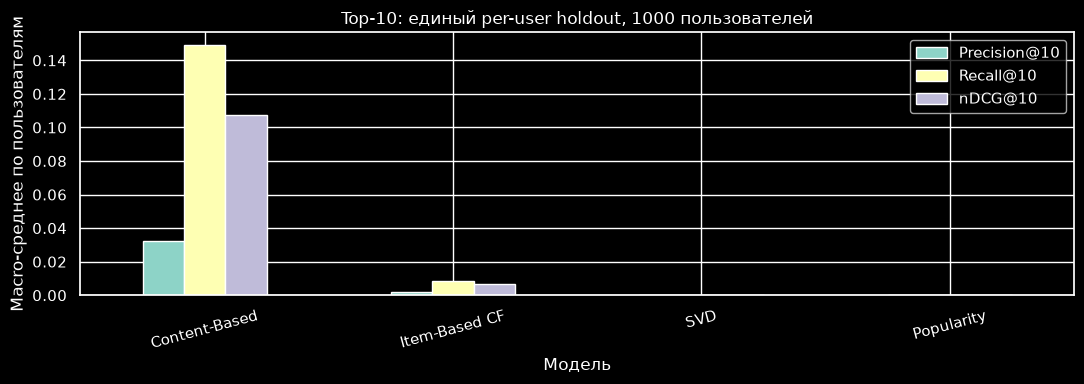

In [74]:
comparison = pd.DataFrame(
    results, columns=["Модель", f"Precision@{K}", f"Recall@{K}", f"nDCG@{K}"]
).set_index("Модель").sort_values(
    [f"nDCG@{K}", f"Recall@{K}", f"Precision@{K}"], ascending=False
)
display(comparison.round(5))
comparison.plot.bar(figsize=(11, 4), rot=15)
plt.ylabel("Macro-среднее по пользователям")
plt.title(f"Top-{K}: единый per-user holdout, {len(test_users)} пользователей")
plt.tight_layout()
plt.show()


### 5.8. Книги без взаимодействий в train

Дополнительно измеряем качество на релевантных test-книгах, отсутствующих
в train. Кандидаты и уже полученные top-K списки не меняются. В знаменателе
Recall/nDCG оставляем только релевантные cold-книги; оцениваем только
пользователей с такими книгами из той же подвыборки. Это диагностический
срез естественного holdout, а не отдельное гарантированно репрезентативное
исследование холодного старта. При отсутствии таких случаев таблица не строится.
Для эксперимента с новыми книгами нужен отдельный item-disjoint split и
метаданные, доступные до появления тестовых взаимодействий.


In [75]:
cold_book_ids = set(book_ids) - set(train_df["book_id"])
cold_relevant = {
    user_id: relevant_items[user_id] & cold_book_ids for user_id in test_users
    if relevant_items[user_id] & cold_book_ids
}
print("Книг каталога без train-взаимодействий:", len(cold_book_ids))
print("Пользователей с релевантными cold-книгами:", len(cold_relevant))
cold_comparison = pd.DataFrame()
if cold_relevant:
    cold_rows = []
    for name, recommendations in recommendations_by_model.items():
        values = [ranking_metrics(recommendations[u], relevant, K)
                  for u, relevant in cold_relevant.items()]
        cold_rows.append([name, *np.mean(values, axis=0)])
    cold_comparison = pd.DataFrame(cold_rows, columns=[
        "Модель", f"Precision@{K}", f"Recall@{K}", f"nDCG@{K}"
    ]).set_index("Модель").sort_values(f"nDCG@{K}", ascending=False)
    display(cold_comparison.round(5))
else:
    print("Срез пуст: выводы о качестве cold-start по этому разбиению невозможны.")


Книг каталога без train-взаимодействий: 0
Пользователей с релевантными cold-книгами: 0
Срез пуст: выводы о качестве cold-start по этому разбиению невозможны.


### 5.9. Диагностика различий моделей

Помимо метрик проверяем, насколько модели повторяют одни и те же книги,
насколько оценены рекомендуемые книги в train и сколько прогнозов SVD
упирается в верхнюю границу шкалы. Для CF отдельно измеряем долю рекомендаций,
действительно поддержанных соседями. Эти показатели помогают интерпретации,
но не заменяют отдельные эксперименты и проверку статистической значимости.


In [76]:
diagnostic_rows = []
for name, recommendations in recommendations_by_model.items():
    recommended_ids = np.array([item for items in recommendations.values() for item in items])
    counts = train_books["ratings_count"].reindex(recommended_ids, fill_value=0)
    frequencies = pd.Series(recommended_ids).value_counts()
    diagnostic_rows.append([
        name, len(frequencies),
        counts.mean() if len(counts) else 0,
        float((counts <= 5).mean()) if len(counts) else 0,
        float(frequencies.head(K).sum() / len(recommended_ids)) if len(recommended_ids) else 0,
    ])
recommendation_diagnostics = pd.DataFrame(diagnostic_rows, columns=[
    "Модель", "Разных книг в рекомендациях", "Среднее число train-оценок книги",
    "Доля рекомендаций книг с ≤5 train-оценками", "Доля рекомендаций в K самых частых книгах",
]).set_index("Модель")
display(recommendation_diagnostics.round(4))

svd_saturated_counts = []
cf_supported = 0
cf_recommended_count = 0
for user_id in test_users:
    unseen = ~np.isin(book_ids, list(train_user_items[user_id]))
    svd_saturated_counts.append(int((svd_scores(user_id)[unseen] >= model.trainset.rating_scale[1]).sum()))
    history = cf_matrix.getrow(cf_users.categories.get_loc(user_id)).copy()
    history.data = np.ones_like(history.data)
    support = (cf_similarity @ history.T).toarray().ravel() > 0
    recommended = recommendations_by_model["Item-Based CF"][user_id]
    positions = np.searchsorted(book_ids, recommended)
    cf_supported += int(support[positions].sum())
    cf_recommended_count += len(recommended)
cf_support_share = cf_supported / cf_recommended_count if cf_recommended_count else 0
content_fallback_share = float(np.mean([
    user_id not in content_users.categories for user_id in test_users
]))
print(f"SVD: среднее число непрочитанных книг с прогнозом 5: {np.mean(svd_saturated_counts):.1f}")
print(f"CF: доля рекомендаций с ненулевой поддержкой соседей: {cf_support_share:.1%}")
print(f"Content: доля пользователей без положительной train-истории: {content_fallback_share:.1%}")


,Разных книг в рекомендациях,Среднее число train-оценок книги,Доля рекомендаций книг с ≤5 train-оценками,Доля рекомендаций в K самых частых книгах
Модель,,,,
Popularity,11,79.6051,0.0,0.9987
Item-Based CF,3601,79.5879,0.0,0.1931
SVD,664,78.9193,0.0,0.3469
Content-Based,3947,79.2151,0.0,0.0515


SVD: среднее число непрочитанных книг с прогнозом 5: 130.0
CF: доля рекомендаций с ненулевой поддержкой соседей: 80.7%
Content: доля пользователей без положительной train-истории: 5.1%


## 6. Гибридизация и выводы

### Интерпретация и ограничения

Порядок моделей и наблюдаемые значения формируются ниже из текущего расчёта,
а не переносятся из старого глобального разбиения. Объяснения — проверяемые
гипотезы о механизмах моделей, а не доказательство причин различий.

- **Popularity:** общий список не учитывает вкус пользователя. Здесь это рейтинг
  по среднему с минимальным порогом одной train-оценки. Он не равнозначен
  популярности по числу читателей. Малые выборки могут завышать среднее;
  наличие таких случаев проверяем диагностической таблицей, а не предполагаем.
  Сглаживание или сортировка по числу взаимодействий — отдельный эксперимент.
- **Item-Based CF:** использует локальные совпадения читателей. Разреженность,
  короткая история и усечение соседей ограничивают покрытие. Если подходящих
  соседей нет, одинаковые fallback-оценки дают порядок по ID. Это помогает
  объяснить возможное отставание от моделей с глобальными факторами.
- **SVD:** совместно оценивает смещения и скрытые предпочтения по всему train,
  поэтому может обобщать лучше локальных совпадений. Однако низкий RMSE сам
  по себе не гарантирует высокий nDCG; у книг без train-взаимодействий нет
  обученных факторов, а одинаковые прогнозы после clipping создают ничьи.
- **Content-Based:** переносит предпочтения из положительной train-истории на
  похожие названия и теги. Признаки могут отражать общие полки/жанры, а не
  индивидуальную оценку. Метод может ранжировать книгу без train-оценок,
  но не решает холодный старт пользователя без истории и не доказывает
  качество на действительно новых книгах с отсутствующими тегами.

### Гибридизация

Для нового пользователя нужен популярностный fallback или сбор интересов.
Для книги без взаимодействий можно использовать метаданные; по мере накопления
оценок увеличивать вклад CF/SVD. Веса гибрида и параметры следует выбирать
на отдельной validation-части внутри train, сохраняя test для финального сравнения.
Полезно проверить сглаженную популярность, дополнительные поля авторов/жанров
и эмбеддинги текстов. Качество зависит от структуры истории, а 5–10 оценок
сами по себе не гарантируют устойчивой персонализации.


In [77]:
mechanisms = {
    "Popularity": "Общий список по среднему рейтингу не учитывает личные интересы и отличается от популярности по числу читателей.",
    "Item-Based CF": "Локальные соседи ограничены разреженностью истории и усечением графа; без совпадений срабатывает fallback.",
    "SVD": "Глобальные факторы оптимизируют ошибку рейтинга, а не top-N; проверяем ограничения ранжирования и ничьи после clipping.",
    "Content-Based": "Текстовая близость даёт перенос по метаданным, но совпадение тегов не обязательно означает высокую личную оценку.",
}
lines = [f"### Наблюдаемый порядок по nDCG@{K}", ""]
for position, (name, row) in enumerate(comparison.iterrows(), start=1):
    lines.append(
        f"{position}. **{name}** — nDCG={row[f'nDCG@{K}']:.5f}, "
        f"Precision={row[f'Precision@{K}']:.5f}, Recall={row[f'Recall@{K}']:.5f}. "
        + mechanisms[name]
    )
leader = comparison.index[0]
runner_up = comparison.index[1]
gap = comparison.iloc[0][f"nDCG@{K}"] - comparison.iloc[1][f"nDCG@{K}"]
lines.extend(["", f"На этой подвыборке первый результат у **{leader}**; "
              f"разница с **{runner_up}** по nDCG составляет {gap:.5f}. "
              "Статистическая значимость не проверялась; при равенстве это не преимущество."])
if not cold_comparison.empty:
    lines.extend(["", f"В срезе cold-книг оценено {len(cold_relevant)} пользователей. "
                  "Сравнивать его с общим рейтингом напрямую нельзя: различаются релевантные множества и состав пользователей."])
lines.extend(["", "### Что помогает объяснить этот порядок", ""])
for name in comparison.index:
    diagnostic = recommendation_diagnostics.loc[name]
    lines.append(
        f"- **{name}:** {int(diagnostic['Разных книг в рекомендациях'])} разных книг; "
        f"на {K} самых часто рекомендуемых книг приходится "
        f"{diagnostic['Доля рекомендаций в K самых частых книгах']:.1%} выдачи; "
        f"книги с ≤5 train-оценками составляют "
        f"{diagnostic['Доля рекомендаций книг с ≤5 train-оценками']:.1%}."
    )
lines.extend([
    "", f"У SVD в среднем {np.mean(svd_saturated_counts):.1f} непрочитанных книг "
    "на верхней границе шкалы. Если их больше K, порядок внутри этой группы "
    "определяется ID: хороший прогноз рейтинга не обеспечивает хороший top-N.",
    f"У CF {cf_support_share:.1%} рекомендаций поддержаны соседями; "
    "оставшаяся доля использует одинаковый fallback пользователя.",
    f"Контентная модель использует положительную историю; "
    f"для {content_fallback_share:.1%} пользователей её нет и используется Popularity.",
    "Наблюдаемые различия согласуются с разными источниками сигнала: "
    "Content-Based переносит тематические предпочтения по метаданным, CF — по общим читателям, "
    "SVD — через факторы рейтингов, а Popularity не персонализирован. "
    "Это интерпретация текущего порядка, не доказательство причин; "
    "для проверки нужны отдельные эксперименты на validation.",
])
display(Markdown("\n".join(lines)))


### Наблюдаемый порядок по nDCG@10

1. **Content-Based** — nDCG=0.10716, Precision=0.03230, Recall=0.14924. Текстовая близость даёт перенос по метаданным, но совпадение тегов не обязательно означает высокую личную оценку.
2. **Item-Based CF** — nDCG=0.00689, Precision=0.00220, Recall=0.00831. Локальные соседи ограничены разреженностью истории и усечением графа; без совпадений срабатывает fallback.
3. **SVD** — nDCG=0.00041, Precision=0.00040, Recall=0.00043. Глобальные факторы оптимизируют ошибку рейтинга, а не top-N; проверяем ограничения ранжирования и ничьи после clipping.
4. **Popularity** — nDCG=0.00000, Precision=0.00000, Recall=0.00000. Общий список по среднему рейтингу не учитывает личные интересы и отличается от популярности по числу читателей.

На этой подвыборке первый результат у **Content-Based**; разница с **Item-Based CF** по nDCG составляет 0.10027. Статистическая значимость не проверялась; при равенстве это не преимущество.

### Что помогает объяснить этот порядок

- **Content-Based:** 3947 разных книг; на 10 самых часто рекомендуемых книг приходится 5.1% выдачи; книги с ≤5 train-оценками составляют 0.0%.
- **Item-Based CF:** 3601 разных книг; на 10 самых часто рекомендуемых книг приходится 19.3% выдачи; книги с ≤5 train-оценками составляют 0.0%.
- **SVD:** 664 разных книг; на 10 самых часто рекомендуемых книг приходится 34.7% выдачи; книги с ≤5 train-оценками составляют 0.0%.
- **Popularity:** 11 разных книг; на 10 самых часто рекомендуемых книг приходится 99.9% выдачи; книги с ≤5 train-оценками составляют 0.0%.

У SVD в среднем 130.0 непрочитанных книг на верхней границе шкалы. Если их больше K, порядок внутри этой группы определяется ID: хороший прогноз рейтинга не обеспечивает хороший top-N.
У CF 80.7% рекомендаций поддержаны соседями; оставшаяся доля использует одинаковый fallback пользователя.
Контентная модель использует положительную историю; для 5.1% пользователей её нет и используется Popularity.
Наблюдаемые различия согласуются с разными источниками сигнала: Content-Based переносит тематические предпочтения по метаданным, CF — по общим читателям, SVD — через факторы рейтингов, а Popularity не персонализирован. Это интерпретация текущего порядка, не доказательство причин; для проверки нужны отдельные эксперименты на validation.